Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.1 MB/s eta 0:00:00
LOADED ARTIFACT: /content/drive/MyDrive/FYP/data/processed/oof_ds1_v6_subjectfolds.npz
SHA256          : 7138c8cf977be01aa1116ab78cab49da344413fd8ec5d8551846f39e37ab1e6c
OUTPUT DIRECTORY: /content/drive/MyDrive/FYP/data/processed/phase3_v6_subjectfolds_r2
keys: ['logits', 'y', 'rec', 'ridx', 'fold', 'seeds']
other artifact (NOT used): logits identical? False | folds identical? False
artifact audit passed: shapes, labels vs beats table, record ids, fold layout
Suspicious-record alignment audit (descriptive; inspect beat_prediction_alignment_audit.csv):
 record    n  correct  mean_confidence  first_r_idx  last_r_idx  unique_labels  unique_predictions  accuracy
    115 1952      209           0.6116          161      649647              1                   2    0.1071
    118 2277       93           0.9146          369      649742              3                   3    0.0408
    207 1

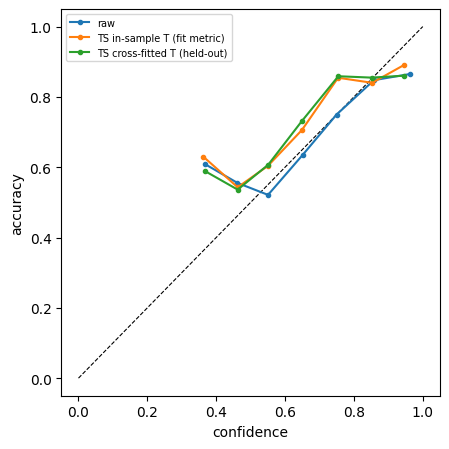

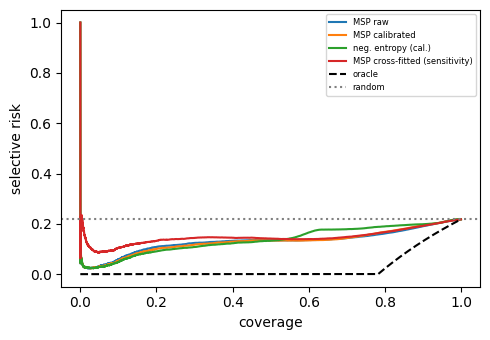

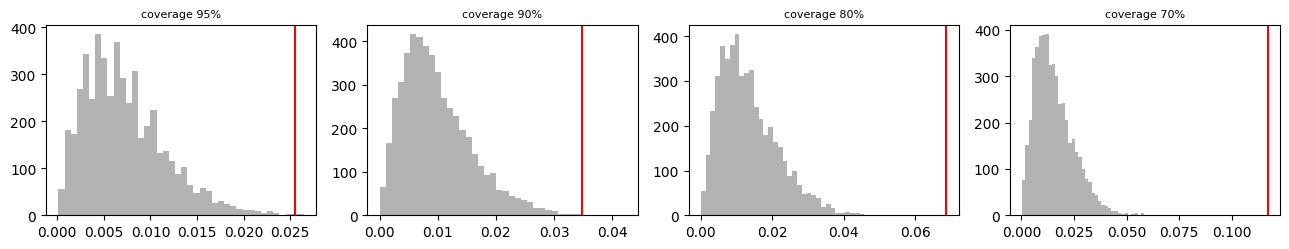

In [1]:
# =====================================================================================
# 03_confidence_rejection.ipynb  --  rerun on oof_ds1_v6_subjectfolds.npz
# No model is trained. The input artifact is only read. All outputs go to a NEW versioned directory.
# CELL 1 and CELL 2 REPLACE the old cell 1. CELLS 3-5 keep the old definitions (cells 2-4 of the old
# notebook, same formulas) with the additions listed in the comments. CELLS 6-10 are new.
# =====================================================================================

# ===== CELL 1: setup, artifact path, versioned output directory =====
from google.colab import drive
drive.mount('/content/drive')
!pip install -q wfdb
import os, sys, json, hashlib, platform, datetime
os.chdir('/content/drive/MyDrive/FYP'); sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, scipy, matplotlib.pyplot as plt
from scipy.special import softmax, log_softmax
from src import config as C
from src.data import load_beats
from src.calibration import fit_temperature, ece, brier
from src.selective import *

ARTIFACT = C.PROC / 'oof_ds1_v6_subjectfolds.npz'            # PRIMARY artifact (the only file read)
ARTIFACT_SHA256 = '7138c8cf977be01aa1116ab78cab49da344413fd8ec5d8551846f39e37ab1e6c'

# expected properties of the primary artifact (values from log sections 12 and 12.1)
EXPECT = dict(
    n=53138, seeds=[42, 43, 44], class_counts=[47917, 999, 3807, 415], n_dropped_edge=11,
    folds={0: [109, 118, 119, 115, 230], 1: [207, 106, 202, 201, 112, 122],
           2: [208, 124, 114, 116], 3: [203, 209, 101, 108], 4: [205, 215, 220, 223]},
    fold_beats={0: 11002, 1: 13000, 2: 8860, 3: 9605, 4: 10671},
    seed_acc=[0.752, 0.718, 0.748], ens_acc=0.782)

LEVELS = [1.0, 0.95, 0.9, 0.8, 0.7]          # unchanged from the old notebook
COV_LEVELS = [0.95, 0.9, 0.8, 0.7]           # matched-coverage levels for class coverage / gap
B_BOOT, R_NULL = 2000, 5000                  # subject bootstrap resamples; beat-level random-rejection replicates
BOOT_SEED, PAIRED_NULL_SEED, BEAT_NULL_SEED = 2026, 2027, 2028

def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

assert ARTIFACT.exists(), f'missing {ARTIFACT}'
sha_before = sha256_of(ARTIFACT)
print('LOADED ARTIFACT:', ARTIFACT)
print('SHA256          :', sha_before)
assert sha_before == ARTIFACT_SHA256, 'SHA256 differs from the audited primary artifact'

k_ver = 1
while (C.PROC / f'phase3_v6_subjectfolds_r{k_ver}').exists():
    k_ver += 1
OUT = C.PROC / f'phase3_v6_subjectfolds_r{k_ver}'
OUT.mkdir(parents=True, exist_ok=False)                      # never reuse or overwrite a previous run
assert OUT.parent == C.PROC and OUT != ARTIFACT
print('OUTPUT DIRECTORY:', OUT)

def save_df(name, df, index=False):
    p = OUT / name
    assert not p.exists(), p
    df.to_csv(p, index=index)
    return p

def save_fig(fig, name):
    p = OUT / name
    assert not p.exists(), p
    fig.savefig(p, dpi=200, bbox_inches='tight')
    return p


# ===== CELL 2: load the artifact and audit it (replaces the old data-loading lines) =====
d = np.load(ARTIFACT)
print('keys:', d.files)
L, y, rec = d['logits'], d['y'], d['rec']                    # L: [seed, n, 4]
n = EXPECT['n']
assert L.shape == (len(EXPECT['seeds']), n, 4), L.shape
assert y.shape == (n,) and rec.shape == (n,)
assert np.isfinite(L).all(), 'non-finite logits: some rows were not out-of-fold predicted'
assert set(np.unique(y)) == {0, 1, 2, 3}
assert np.bincount(y, minlength=4).tolist() == EXPECT['class_counts'], np.bincount(y, minlength=4)
if 'seeds' in d.files:
    assert [int(s) for s in d['seeds']] == EXPECT['seeds'], d['seeds']

# records: exactly the 23 DS1 primary records
assert set(int(r) for r in np.unique(rec)) == set(C.DS1_PRIMARY), 'record set differs from DS1_PRIMARY'
assert len(np.unique(rec)) == 23

# labels and record ids must agree with the beats table (independent of the artifact)
assert 'ridx' in d.files, 'artifact has no ridx; cannot cross-check labels'
ridx = d['ridx']
assert ridx.shape == (n,)
tbl = load_beats(); tbl = tbl[tbl.split == 'DS1']
assert len(tbl) - n == EXPECT['n_dropped_edge'], (len(tbl), n)     # Audit A: 11 edge beats
chk = pd.DataFrame({'record': rec.astype(int), 'r_idx': ridx.astype(int)})
assert not chk.duplicated(['record', 'r_idx']).any(), 'duplicate (record, r_idx) rows'
chk = chk.merge(tbl[['record', 'r_idx', 'aami']], on=['record', 'r_idx'], how='left', validate='one_to_one')
assert chk.aami.notna().all(), 'artifact rows missing from the beats table'
assert (chk.aami.map(C.CLS2IDX).values == y).all(), 'artifact labels disagree with the beats table'

# corrected subject-grouped fold layout (log section 12, Audit B)
rec2fold = {r: k for k, rs in EXPECT['folds'].items() for r in rs}
assert set(rec2fold) == set(C.DS1_PRIMARY) and len(rec2fold) == 23
assert rec2fold[201] == rec2fold[202], '201 and 202 are one subject and must share a fold'
fold_id = np.array([rec2fold[int(r)] for r in rec])
if 'fold' in d.files:
    assert np.array_equal(d['fold'], fold_id), 'stored fold ids differ from the corrected layout'
else:
    print('NOTE: artifact has no stored fold array; fold ids come from the corrected layout above')
assert {k: int((fold_id == k).sum()) for k in range(5)} == EXPECT['fold_beats']

# statistical unit = subject (201 and 202 merged)
subj = np.where(rec == 202, 201, rec)
subjects = np.unique(subj)
idx_by = {s: np.where(subj == s)[0] for s in subjects}
assert len(subjects) == 22

# informational only: the other artifact (not used for any result below)
_b = C.PROC / 'oof_ds1_v6_base.npz'
if _b.exists():
    _bd = np.load(_b)
    print('other artifact (NOT used): logits identical?', _bd['logits'].shape == L.shape and np.allclose(_bd['logits'], L),
          '| folds identical?', ('fold' in _bd.files) and np.array_equal(_bd['fold'], fold_id))
print('artifact audit passed: shapes, labels vs beats table, record ids, fold layout')


# ===== CELL 3: ensemble and calibration (old cell 2 + cross-fitted estimates) =====
Lens = L.mean(0)                                            # ensemble by logit averaging (unchanged)
pred = Lens.argmax(1); correct = pred == y

# Beat-to-prediction alignment audit (especially records flagged for unusually high error).
audit_beats = pd.DataFrame({
    'record': rec.astype(int), 'r_idx': ridx.astype(int), 'fold': fold_id.astype(int),
    'y_true_idx': y.astype(int), 'y_pred_idx': pred.astype(int),
    'confidence_msp_raw': softmax(Lens, axis=1).max(axis=1),
    'correct': correct.astype(bool)
})
audit_beats = audit_beats.merge(
    tbl[['record', 'r_idx', 'aami']], on=['record', 'r_idx'], how='left',
    validate='one_to_one', suffixes=('', '_table')
)
assert audit_beats['aami'].notna().all()
assert (audit_beats['y_true_idx'] == audit_beats['aami'].map(C.CLS2IDX).to_numpy()).all()
audit_beats['y_true'] = audit_beats['y_true_idx'].map({v: k for k, v in C.CLS2IDX.items()})
audit_beats['y_pred'] = audit_beats['y_pred_idx'].map({v: k for k, v in C.CLS2IDX.items()})
save_df('beat_prediction_alignment_audit.csv', audit_beats, index=False)

suspect_records = [118, 115, 207]
suspect_summary = (audit_beats[audit_beats.record.isin(suspect_records)]
    .groupby('record')
    .agg(n=('correct', 'size'), correct=('correct', 'sum'),
         mean_confidence=('confidence_msp_raw', 'mean'),
         first_r_idx=('r_idx', 'min'), last_r_idx=('r_idx', 'max'),
         unique_labels=('y_true', 'nunique'), unique_predictions=('y_pred', 'nunique'))
    .reset_index())
suspect_summary['accuracy'] = suspect_summary['correct'] / suspect_summary['n']
print('Suspicious-record alignment audit (descriptive; inspect beat_prediction_alignment_audit.csv):')
print(suspect_summary.round(4).to_string(index=False))
save_df('suspect_record_alignment_summary.csv', suspect_summary, index=False)

seed_acc = [(L[s].argmax(1) == y).mean() for s in range(L.shape[0])]
print('ensemble acc', correct.mean().round(3), '| seed acc', np.round(seed_acc, 3))
assert abs(correct.mean() - EXPECT['ens_acc']) < 0.002, 'ensemble accuracy differs from the audited 0.782: wrong artifact?'
assert np.allclose(np.round(seed_acc, 3), EXPECT['seed_acc'], atol=0.0011)

T = fit_temperature(Lens, y)                                # CALIBRATION-FIT (in-sample): T fitted on the same logits it is evaluated on
P_raw, P_cal = softmax(Lens, 1), softmax(Lens / T, 1)

# CROSS-FITTED (held-out T): for each fold, T is fitted on the OTHER folds' out-of-fold logits and applied to that fold
T_cf, Lcf = {}, np.empty_like(Lens)
for k in range(5):
    m = fold_id == k
    T_cf[k] = fit_temperature(Lens[~m], y[~m])
    Lcf[m] = Lens[m] / T_cf[k]
P_cf = softmax(Lcf, 1)

nll = lambda P: float(-np.log(P[np.arange(len(y)), y] + 1e-12).mean())
cal_tab = pd.DataFrame([
    ['raw (no calibration)', ece(P_raw, y), brier(P_raw, y), nll(P_raw)],
    [f'temperature-scaled, IN-SAMPLE T={T:.3f} (calibration-fit, optimistic)', ece(P_cal, y), brier(P_cal, y), nll(P_cal)],
    ['temperature-scaled, CROSS-FITTED T (held-out folds)', ece(P_cf, y), brier(P_cf, y), nll(P_cf)]],
    columns=['calibration', 'ECE', 'Brier', 'NLL'])
print(cal_tab.round(4).to_string(index=False))
print('cross-fitted T per held-out fold:', {k: round(v, 3) for k, v in T_cf.items()})
print('Only the CROSS-FITTED row is a held-out calibration estimate. The in-sample row is a fit metric.')
save_df('calibration_table.csv', cal_tab)

# per-seed spread (each seed with its own in-sample T)
rows = []
for s, sd in enumerate(EXPECT['seeds']):
    Ts = fit_temperature(L[s], y); Pr, Pc = softmax(L[s], 1), softmax(L[s] / Ts, 1); cs = Pr.argmax(1) == y
    rows.append([sd, cs.mean(), Ts, aurc(Pr.max(1), cs), aurc(Pc.max(1), cs), ece(Pr, y), ece(Pc, y)])
seed_tab = pd.DataFrame(rows, columns=['seed', 'acc', 'T(in-sample)', 'AURC MSP raw', 'AURC MSP cal.', 'ECE raw', 'ECE TS (in-sample)'])
print(seed_tab.round(4).to_string(index=False)); save_df('per_seed_table.csv', seed_tab)


# ===== CELL 4: risk-coverage (old cell 3 + one added sensitivity row) =====
scores = {'MSP raw': P_raw.max(1), 'MSP calibrated': P_cal.max(1),
          'neg. entropy (cal.)': (P_cal * np.log(P_cal + 1e-12)).sum(1),
          'MSP cross-fitted (sensitivity)': P_cf.max(1)}      # added row; primary score is still 'MSP calibrated'
base_risk = 1 - correct.mean()
rows = []
for name, s in scores.items():
    rows.append([name, round(aurc(s, correct), 4)] +
                [round(selective_risk(accept_at_coverage(s, c), correct), 4) for c in LEVELS])
rows.append(['random', round(base_risk, 4)] + [round(base_risk, 4)] * len(LEVELS))
rows.append(['oracle', round(aurc(correct.astype(float), correct), 4)] +
            [round(selective_risk(oracle_accept(correct, c), correct), 4) for c in LEVELS])
rc_tab = pd.DataFrame(rows, columns=['method', 'AURC'] + [f'risk@{int(c*100)}%' for c in LEVELS])
print(rc_tab.to_string(index=False)); save_df('risk_coverage_table.csv', rc_tab)


# ===== CELL 5: class coverage at matched overall coverage (old cell 4) =====
s = scores['MSP calibrated']
out = []
for c in COV_LEVELS:
    cc = class_coverage(accept_at_coverage(s, c), y)
    out.append([f'{int(c*100)}%', *cc.round(3), round(np.nanmax(cc[:3]) - np.nanmin(cc[:3]), 3)])
cov_tab = pd.DataFrame(out, columns=['coverage'] + C.CLASSES + ['gap N/S/V'])
print(cov_tab.to_string(index=False)); print('F is descriptive only (one dominant record).')
save_df('class_coverage_table.csv', cov_tab)


# ===== CELL 6 (new): error by record and by fold, 80% coverage, calibrated MSP =====
acc80 = accept_at_coverage(scores['MSP calibrated'], 0.8)
dfr = pd.DataFrame({'rec': rec, 'err': ~correct, 'rej80': ~acc80})
t = dfr.groupby('rec').agg(n=('err', 'size'), errors=('err', 'sum'), rejected=('rej80', 'sum'))
t['fold'] = [rec2fold[int(r)] for r in t.index]
t['acc'] = 1 - t.errors / t.n
t['err_share'] = t.errors / t.errors.sum()
t['frac_rejected'] = t.rejected / t.n
t['errors_removed'] = dfr[dfr.err & dfr.rej80].groupby('rec').size().reindex(t.index).fillna(0)
t['frac_err_removed'] = np.where(t.errors > 0, t.errors_removed / t.errors, np.nan)
top = t.sort_values('err_share', ascending=False)
print(top.head(10).round(3).to_string())
print('top-3 records share of all errors:', round(top.err_share.head(3).sum(), 3), list(top.index[:3]))
print('overall errors removed at 80% coverage:', round(dfr[dfr.err & dfr.rej80].shape[0] / dfr.err.sum(), 3), '(random 0.20, oracle 1.00)')
print('Per-record rows are descriptive (the record is the sampling unit; no interval is given for a single record).')
save_df('error_by_record.csv', top.reset_index(), index=False)
ft = dfr.assign(fold=fold_id).groupby('fold').agg(n=('err', 'size'), acc=('err', lambda e: 1 - e.mean()))
print(ft.round(3).to_string()); save_df('accuracy_by_fold.csv', ft.reset_index())


# ===== CELL 7 (new): reliability diagram and risk-coverage plot =====
conf_ok = {'raw': P_raw, 'TS in-sample T (fit metric)': P_cal, 'TS cross-fitted T (held-out)': P_cf}
def reliability(P, n_bins=10, min_n=30):
    conf, ok = P.max(1), (P.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1); rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= min_n:
            rows.append([lo, hi, int(m.sum()), conf[m].mean(), ok[m].mean()])
    return pd.DataFrame(rows, columns=['bin_lo', 'bin_hi', 'n', 'mean_conf', 'accuracy'])
fig, ax = plt.subplots(figsize=(4.6, 4.6)); ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
rel_all = []
for name, P in conf_ok.items():
    r_ = reliability(P); ax.plot(r_.mean_conf, r_.accuracy, marker='o', ms=3, label=name); rel_all.append(r_.assign(calibration=name))
ax.set_xlabel('confidence'); ax.set_ylabel('accuracy'); ax.legend(fontsize=7); plt.tight_layout()
save_fig(fig, 'reliability_diagram.png'); save_df('reliability_bins.csv', pd.concat(rel_all))
fig, ax = plt.subplots(figsize=(5, 3.5))
for name, s_ in scores.items():
    cov, risk = risk_coverage(s_, correct); ax.plot(cov, risk, label=name)
cov, risk = risk_coverage(correct.astype(float), correct); ax.plot(cov, risk, 'k--', label='oracle')
ax.axhline(base_risk, color='grey', ls=':', label='random')
ax.set_xlabel('coverage'); ax.set_ylabel('selective risk'); ax.legend(fontsize=6); plt.tight_layout()
save_fig(fig, 'risk_coverage_curves.png')


# ===== CELL 8 (new): subject-level bootstrap (22 subjects, 201+202 merged), B = 2000 =====
# Resampling unit = subject. T is NOT refitted inside the bootstrap (the intervals are conditional on the fitted T / T_cf).
SC = scores
cls_names = C.CLASSES
edges15 = np.linspace(0, 1, 16)
LPcal = {'raw': P_raw, 'TS in-sample': P_cal, 'TS cross-fitted': P_cf}
conf_i = {k: P.max(1) for k, P in LPcal.items()}
ok_i = {k: (P.argmax(1) == y).astype(float) for k, P in LPcal.items()}
nll_i = {k: -np.log(P[np.arange(n), y] + 1e-12) for k, P in LPcal.items()}
brier_i = {k: ((P - np.eye(4)[y]) ** 2).sum(1) for k, P in LPcal.items()}

def ece_fast(conf, ok):
    b = np.clip(np.searchsorted(edges15, conf, side='left') - 1, 0, 14)
    return np.abs(np.bincount(b, weights=ok, minlength=15) - np.bincount(b, weights=conf, minlength=15)).sum() / len(conf)

def null_gap(yy, rng):                                      # one random rejection replicate at each matched coverage
    m = len(yy); perm = rng.permutation(m); cn = np.bincount(yy, minlength=4).astype(float); out = {}
    for c in COV_LEVELS:
        kk = int(round(c * m)); cv = np.bincount(yy[perm[:kk]], minlength=4) / np.where(cn > 0, cn, np.nan)
        out[c] = np.nanmax(cv[:3]) - np.nanmin(cv[:3])
    return out

def resample_stats(idx):
    yy, cc, m = y[idx], correct[idx], len(idx)
    ks = {c: int(round(c * m)) for c in COV_LEVELS}; kall = np.arange(1, m + 1); tot_err = (~cc).sum(); o = {}
    for nm in SC:
        order = np.argsort(-SC[nm][idx], kind='stable'); cum = np.cumsum(~cc[order])
        o[f'AURC|{nm}'] = (cum / kall).mean()
        for c in COV_LEVELS:
            o[f'risk@{int(c*100)}|{nm}'] = cum[ks[c] - 1] / ks[c]
        if nm == 'MSP calibrated':
            for c in COV_LEVELS:
                acc = np.zeros(m, bool); acc[order[:ks[c]]] = True
                cv = np.array([acc[yy == q].mean() if (yy == q).any() else np.nan for q in range(4)])
                for q, cl in enumerate(cls_names):
                    o[f'cov@{int(c*100)}|{cl}'] = cv[q]
                    o[f'dev@{int(c*100)}|{cl}'] = cv[q] - c            # coverage minus the class-neutral level
                o[f'gap@{int(c*100)}'] = np.nanmax(cv[:3]) - np.nanmin(cv[:3])
                o[f'err_removed@{int(c*100)}'] = 1 - cum[ks[c] - 1] / tot_err if tot_err > 0 else np.nan
    for k in LPcal:
        o[f'ECE|{k}'] = ece_fast(conf_i[k][idx], ok_i[k][idx]); o[f'Brier|{k}'] = brier_i[k][idx].mean(); o[f'NLL|{k}'] = nll_i[k][idx].mean()
    o['ECE diff|cross-fitted - raw'] = o['ECE|TS cross-fitted'] - o['ECE|raw']
    o['AURC diff|entropy - MSP cal.'] = o['AURC|neg. entropy (cal.)'] - o['AURC|MSP calibrated']
    o['AURC diff|MSP cal. - MSP raw'] = o['AURC|MSP calibrated'] - o['AURC|MSP raw']
    o['AURC diff|MSP cross-fitted - MSP cal.'] = o['AURC|MSP cross-fitted (sensitivity)'] - o['AURC|MSP calibrated']
    return o

point = resample_stats(np.arange(n))
# the fast statistics must reproduce the reference implementations on the full data
assert abs(point['AURC|MSP calibrated'] - aurc(scores['MSP calibrated'], correct)) < 1e-9
assert abs(point['risk@80|MSP calibrated'] - selective_risk(accept_at_coverage(scores['MSP calibrated'], 0.8), correct)) < 1e-9
assert abs(point['ECE|TS in-sample'] - ece(P_cal, y)) < 1e-6 and abs(point['ECE|raw'] - ece(P_raw, y)) < 1e-6

rng, null_rng = np.random.default_rng(BOOT_SEED), np.random.default_rng(PAIRED_NULL_SEED)
draws = []
for b in range(B_BOOT):
    pick = rng.choice(subjects, len(subjects), replace=True)
    idx = np.concatenate([idx_by[s_] for s_ in pick])
    r = resample_stats(idx); ng = null_gap(y[idx], null_rng)
    for c in COV_LEVELS:
        r[f'nullgap@{int(c*100)}'] = ng[c]; r[f'gap_minus_null@{int(c*100)}'] = r[f'gap@{int(c*100)}'] - ng[c]
    draws.append(r)
    if (b + 1) % 500 == 0: print('bootstrap', b + 1, '/', B_BOOT)
boot = pd.DataFrame(draws)

rows = []
for k in boot.columns:
    lo, hi = np.nanpercentile(boot[k], [2.5, 97.5])
    is_contrast = k.startswith(('dev@', 'gap_minus_null@', 'AURC diff', 'ECE diff'))     # flag only contrasts that have a natural 0
    rows.append([k, point.get(k, np.nan), np.nanmedian(boot[k]), lo, hi, int(boot[k].notna().sum()),
                 (bool(lo > 0 or hi < 0) if is_contrast else None)])
boot_tab = pd.DataFrame(rows, columns=['stat', 'point', 'boot_median', 'ci_lo', 'ci_hi', 'n_valid', 'contrast_interval_excludes_0'])
save_df('bootstrap_summary.csv', boot_tab)
np.savez_compressed(OUT / 'bootstrap_draws.npz', cols=np.array(boot.columns), values=boot.values,
                    seed=BOOT_SEED, paired_null_seed=PAIRED_NULL_SEED, B=B_BOOT)
show = lambda pre: print(boot_tab[boot_tab.stat.str.startswith(pre)].round(4).to_string(index=False))
print(f'{len(subjects)} subjects, {B_BOOT} resamples, 95% percentile intervals, T not refitted')
print('\n-- calibration (ECE/Brier/NLL; in-sample = fit metric, cross-fitted = held-out T) --')
for p_ in ['ECE|', 'Brier|', 'NLL|', 'ECE diff']: show(p_)
print('\n-- AURC and risk --');  [show(p_) for p_ in ['AURC|', 'AURC diff', 'risk@']]
print('\n-- class coverage minus overall coverage (0 = class-neutral); F descriptive --'); show('dev@')
print('\n-- N/S/V coverage gap, paired null, errors removed --'); [show(p_) for p_ in ['gap@', 'nullgap@', 'gap_minus_null@', 'err_removed@']]
print('NOTE: gap = max-min coverage is >= 0 by construction; use gap_minus_null (paired random-rejection null), not gap > 0.')


# ===== CELL 9 (new): random-rejection null for the N/S/V coverage gap, R = 5000, beat level =====
# Procedure: for each replicate, draw one uniformly random permutation of all DS1 beats (seed BEAT_NULL_SEED). At each matched
# overall coverage c, accept the first round(c*n) beats of that permutation (nested prefixes across c; each level is marginally a
# uniform random subset of size round(c*n)). Class coverage = accepted/total per true class; gap = max - min over N, S, V.
# p = (1 + #{null gap >= observed gap}) / (1 + R), one-sided. This null treats beats as exchangeable (ignores subject clustering),
# so its one-sided p-value is descriptive/exploratory, NOT subject-cluster-robust. The primary uncertainty summary is the subject bootstrap contrast in CELL 8; it still uses a beat-randomization null within each resampled subject-bootstrap sample.
rngn = np.random.default_rng(BEAT_NULL_SEED); cls_n = np.bincount(y, minlength=4)
null_cov = {c: np.empty((R_NULL, 4)) for c in COV_LEVELS}
for r_ in range(R_NULL):
    perm = rngn.permutation(n)
    for c in COV_LEVELS:
        null_cov[c][r_] = np.bincount(y[perm[:int(round(c * n))]], minlength=4) / cls_n
rows = []; fig, axs = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, c in zip(axs, COV_LEVELS):
    ng = null_cov[c][:, :3].max(1) - null_cov[c][:, :3].min(1); obs = point[f'gap@{int(c*100)}']
    p = (1 + (ng >= obs).sum()) / (1 + R_NULL)
    rows.append([f'{int(c*100)}%', obs, ng.mean(), *np.percentile(ng, [2.5, 97.5]), ng.max(), p])
    ax.hist(ng, bins=40, color='0.7'); ax.axvline(obs, color='r'); ax.set_title(f'coverage {int(c*100)}%', fontsize=8)
plt.tight_layout(); save_fig(fig, 'gap_null_hist.png')
null_tab = pd.DataFrame(rows, columns=['coverage', 'observed_gap', 'null_mean', 'null_2.5%', 'null_97.5%', 'null_max', 'p_one_sided'])
print(f'Random-rejection null: R={R_NULL} replicates, seed={BEAT_NULL_SEED}; paired bootstrap null seed={PAIRED_NULL_SEED}')
print(null_tab.round(4).to_string(index=False)); save_df('gap_null_summary.csv', null_tab)

# Fill the previously missing observed point estimates in bootstrap_summary.csv.
# Point contrast = observed gap - Monte Carlo mean gap under random beat rejection.
# The percentile interval remains the subject-bootstrap distribution of gap minus one
# paired random-rejection replicate per resample; it includes random-null Monte Carlo noise.
for _, row in null_tab.iterrows():
    c_pct = int(row['coverage'].rstrip('%'))
    gkey, nkey, dkey = f'gap@{c_pct}', f'nullgap@{c_pct}', f'gap_minus_null@{c_pct}'
    null_mean = float(row['null_mean'])
    obs_gap = float(point[gkey])
    point[nkey] = null_mean
    point[dkey] = obs_gap - null_mean
    boot_tab.loc[boot_tab.stat == nkey, 'point'] = null_mean
    boot_tab.loc[boot_tab.stat == dkey, 'point'] = obs_gap - null_mean
tmp_summary = OUT / 'bootstrap_summary_corrected.tmp.csv'
assert not tmp_summary.exists()
boot_tab.to_csv(tmp_summary, index=False)
os.replace(tmp_summary, OUT / 'bootstrap_summary.csv')
print('Corrected point estimates for gap-minus-random-null written to bootstrap_summary.csv')

np.savez_compressed(OUT / 'gap_null_draws.npz', **{f'cov{int(c*100)}': null_cov[c] for c in COV_LEVELS}, seed=BEAT_NULL_SEED, R=R_NULL)


# ===== CELL 10 (new): manifest and final integrity check =====
sha_after = sha256_of(ARTIFACT)
assert sha_after == sha_before == ARTIFACT_SHA256, 'primary artifact changed during the run'
manifest = dict(
    artifact=str(ARTIFACT), artifact_sha256=sha_after, output_dir=str(OUT), n_beats=int(n), n_subjects=int(len(subjects)),
    seeds=EXPECT['seeds'], fold_layout=EXPECT['folds'], T_in_sample=float(T), T_cross_fitted={int(k): float(v) for k, v in T_cf.items()},
    ensemble_acc=float(correct.mean()), bootstrap=dict(B=B_BOOT, seed=BOOT_SEED, paired_null_seed=PAIRED_NULL_SEED, unit='subject (201+202 merged)'),
    beat_level_null=dict(R=R_NULL, seed=BEAT_NULL_SEED, inference='exploratory beat-level exchangeability; p-values not subject-cluster-robust', point_contrast='observed gap minus Monte Carlo mean random-rejection gap'),
    versions=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__),
    created=datetime.datetime.now().isoformat(timespec='seconds'))
with open(OUT / 'manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)
print(sorted(p.name for p in OUT.iterdir()))
print('primary artifact unchanged (SHA256 verified after the run)')

In [2]:
# ===== CELL 11 (new): verify that artifact rows line up with beats and labels; per-record prediction tables =====
# Run in the SAME session after CELL 10 (so OUT is the current run folder). Read-only diagnostic: no training.
import torch
from src.segment import build_dataset
from src.model import BeatCNN
from src.train2 import get_logits, DEVICE

d1 = load_beats(); d1 = d1[d1.split == 'DS1']
X, RR, y2, rec2, ridx2 = build_dataset(d1)

# (a) the artifact's row order must be exactly the order of the dataset the models were trained and evaluated on
assert X.shape[0] == n
assert np.array_equal(rec2, rec) and np.array_equal(ridx2, ridx) and np.array_equal(y2, y), 'artifact row order differs from build_dataset'
print('row order, record ids, r_idx and labels identical to build_dataset: OK')

# (b) the R peak must sit at the window centre (index 90): offset of the largest |amplitude| within +/-10 samples
off = np.abs(X[:, 80:101]).argmax(1) - 10
centred = np.abs(off) <= 4
cen = pd.DataFrame({'rec': rec, 'centred': centred}).groupby('rec').centred.mean()
print('beats with R peak within 4 samples of the window centre: overall', round(centred.mean(), 3))
print(cen.loc[[115, 118, 207]].round(3).to_string())

# (c) in-sample accuracy of the saved final models (trained on ALL of DS1, so they have seen these beats)
Lf = []
for sd in EXPECT['seeds']:
    m = BeatCNN().to(DEVICE)
    m.load_state_dict(torch.load(C.PROC / f'cnn_ds1_seed{sd}.pt', map_location=DEVICE)); m.eval()
    Lf.append(get_logits(m, X, RR))
pf = np.mean(Lf, 0).argmax(1)
rows = []
for r in [115, 118, 207]:
    mk = rec == r
    rows.append([r, int(mk.sum()), float((pred[mk] == y[mk]).mean()), float((pf[mk] == y[mk]).mean())])
align = pd.DataFrame(rows, columns=['record', 'n', 'acc_out_of_fold', 'acc_final_models_in_sample'])
print(align.round(3).to_string(index=False))
print('If label and waveform are aligned, the in-sample accuracy should be clearly higher than the out-of-fold accuracy.')
save_df('alignment_verification_summary.csv', align)

# (d) true versus predicted counts for the suspicious records (out-of-fold ensemble)
names = C.CLASSES
tabs = []
for r in [115, 118, 207]:
    mk = rec == r
    ct = pd.crosstab(pd.Series(np.array(names)[y[mk]], name='true'), pd.Series(np.array(names)[pred[mk]], name='pred'))
    print(f'\nrecord {r}: true (rows) vs predicted (columns), out-of-fold ensemble'); print(ct.to_string())
    tabs.append(ct.reset_index().assign(record=r))
save_df('suspect_record_confusion.csv', pd.concat(tabs, ignore_index=True))



row order, record ids, r_idx and labels identical to build_dataset: OK
beats with R peak within 4 samples of the window centre: overall 0.982
rec
115    1.000
118    0.994
207    0.985
 record    n  acc_out_of_fold  acc_final_models_in_sample
    115 1952            0.107                       1.000
    118 2277            0.041                       0.991
    207 1859            0.167                       0.982
If label and waveform are aligned, the in-sample accuracy should be clearly higher than the out-of-fold accuracy.

record 115: true (rows) vs predicted (columns), out-of-fold ensemble
pred    N     S
true           
N     209  1743

record 118: true (rows) vs predicted (columns), out-of-fold ensemble
pred   N  S     V
true             
N     84  1  2080
S      1  0    95
V      7  0     9

record 207: true (rows) vs predicted (columns), out-of-fold ensemble
pred    N     V
true           
N     108  1434
S       0   107
V       7   203


PosixPath('/content/drive/MyDrive/FYP/data/processed/phase3_v6_subjectfolds_r2/suspect_record_confusion.csv')

In [6]:

import numpy as np
from scipy.special import softmax
from pathlib import Path

ARTIFACT = Path(
    "/content/drive/MyDrive/FYP/data/processed/"
    "oof_ds1_v6_subjectfolds.npz"
)

with np.load(ARTIFACT, allow_pickle=False) as d:
    saved_logits = d["logits"].copy()
    y_null = d["y"].copy()
    rec_null = d["rec"].copy()
    fold_null = d["fold"].copy()

# Average logits across the 3 seeds, matching the project's ensemble rule.
ensemble_logits = saved_logits.mean(axis=0)

# Cross-fitted temperatures from the earlier calibration output.
# Confirm these are the exact values recorded for this artifact.
T_BY_FOLD = {
    0: 1.252,
    1: 1.387,
    2: 1.501,
    3: 1.403,
    4: 1.545,
}

msp_crossfit = np.empty(len(y_null), dtype=np.float64)

for f, temperature in T_BY_FOLD.items():
    mask = fold_null == f
    assert mask.any(), f"No beats found for fold {f}"
    msp_crossfit[mask] = softmax(
        ensemble_logits[mask] / temperature, axis=1
    ).max(axis=1)

assert np.isfinite(msp_crossfit).all()
assert len(msp_crossfit) == len(y_null) == len(rec_null)

print("Cross-fitted MSP created.")
print("Beats:", len(msp_crossfit))
print("Fold counts:", {
    int(f): int((fold_null == f).sum())
    for f in np.unique(fold_null)
})
print("MSP range:", round(msp_crossfit.min(), 4),
      "to", round(msp_crossfit.max(), 4))

Cross-fitted MSP created.
Beats: 53138
Fold counts: {0: 11002, 1: 13000, 2: 8860, 3: 9605, 4: 10671}
MSP range: 0.2825 to 1.0


In [8]:

# ===== CELL 12: within-record random-rejection null =====
# Purpose:
# Test whether the N/S/V class-coverage gap exceeds a null that preserves
# each record's accepted-beat count but randomizes accepted beats within records.
#
# No training. Does not modify the OOF artifact.
# Run after Cell 11, in the same notebook session.

import numpy as np
import pandas as pd
from pathlib import Path

# IMPORTANT:
# Use EXACTLY the confidence score used for the existing class-coverage table.
# Change this line if your notebook uses a different variable.
score = msp_crossfit
y_arr = y_null
rec_arr = rec_null

assert len(score) == len(y) == len(rec), "score/y/rec lengths differ"
assert np.isfinite(score).all(), "Confidence score contains non-finite values"

# Keep the same AAMI label mapping as the earlier cells.
class_names = list(C.CLASSES)
target_classes = ["N", "S", "V"]
class_ids = {name: class_names.index(name) for name in target_classes}

y_arr = np.asarray(y)
rec_arr = np.asarray(rec)
n = len(y_arr)

coverages = [0.95, 0.90, 0.80, 0.70]
R = 5000
rng = np.random.default_rng(2029)

# Stable global ranking: higher confidence = more likely to be accepted.
# The number accepted is fixed exactly at each requested coverage.
ranked = np.argsort(-score, kind="stable")

def class_coverage_gap(accepted):
    """Return per-class coverage and max-minus-min gap for N/S/V."""
    cov = {}
    for name in target_classes:
        mask = (y_arr == class_ids[name])
        cov[name] = (
            float(accepted[mask].mean()) if mask.any() else np.nan
        )
    values = np.array([cov[c] for c in target_classes], dtype=float)
    gap = float(values.max() - values.min())
    return cov, gap

# Record indices are fixed once; randomization happens only within each record.
record_indices = {
    r: np.flatnonzero(rec_arr == r)
    for r in np.unique(rec_arr)
}

results = []
null_rows = []

for target in coverages:
    n_accept = int(round(target * n))
    accepted_obs = np.zeros(n, dtype=bool)
    accepted_obs[ranked[:n_accept]] = True

    obs_cov, obs_gap = class_coverage_gap(accepted_obs)

    # Preserve the observed accepted count in EVERY record.
    accepted_per_record = {
        r: int(accepted_obs[idx].sum())
        for r, idx in record_indices.items()
    }

    null_gaps = np.empty(R, dtype=float)
    null_class_cov = {c: np.empty(R, dtype=float)
                      for c in target_classes}

    for b in range(R):
        accepted_null = np.zeros(n, dtype=bool)

        for r, idx in record_indices.items():
            k = accepted_per_record[r]
            if k > 0:
                chosen = rng.choice(idx, size=k, replace=False)
                accepted_null[chosen] = True

        cov_null, gap_null = class_coverage_gap(accepted_null)
        null_gaps[b] = gap_null

        for c in target_classes:
            null_class_cov[c][b] = cov_null[c]

    # One-sided test: is the observed gap unusually LARGE?
    p_value = (
        1 + np.count_nonzero(null_gaps >= obs_gap)
    ) / (R + 1)

    null_mean = float(null_gaps.mean())
    null_lo, null_hi = np.quantile(null_gaps, [0.025, 0.975])

    row = {
        "target_coverage": target,
        "actual_coverage": float(accepted_obs.mean()),
        "observed_gap_NSV": obs_gap,
        "null_mean_gap": null_mean,
        "observed_minus_null_mean": obs_gap - null_mean,
        "null_2.5pct": float(null_lo),
        "null_97.5pct": float(null_hi),
        "p_one_sided": float(p_value),
        "n_null_replicates": R,
    }

    for c in target_classes:
        row[f"coverage_{c}"] = obs_cov[c]
        row[f"null_mean_coverage_{c}"] = float(
            null_class_cov[c].mean()
        )

    results.append(row)

    for value in null_gaps:
        null_rows.append({
            "target_coverage": target,
            "null_gap_NSV": float(value)
        })

summary = pd.DataFrame(results)
null_draws = pd.DataFrame(null_rows)

out_dir = Path(OUT)
out_dir.mkdir(parents=True, exist_ok=True)

summary_path = out_dir / "within_record_null_summary.csv"
draws_path = out_dir / "within_record_null_draws.csv"

summary.to_csv(summary_path, index=False)
null_draws.to_csv(draws_path, index=False)

print("Within-record null complete")
print(f"Records: {len(record_indices)}")
print(f"Beats: {n}")
print(f"Null replicates per coverage: {R}")
print(summary.round(4).to_string(index=False))
print(f"\nSaved: {summary_path}")
print(f"Saved: {draws_path}")

Within-record null complete
Records: 23
Beats: 53138
Null replicates per coverage: 5000
 target_coverage  actual_coverage  observed_gap_NSV  null_mean_gap  observed_minus_null_mean  null_2.5pct  null_97.5pct  p_one_sided  n_null_replicates  coverage_N  null_mean_coverage_N  coverage_S  null_mean_coverage_S  coverage_V  null_mean_coverage_V
            0.95             0.95            0.0283         0.0321                   -0.0038       0.0235        0.0401       0.8068               5000      0.9502                0.9489      0.9750                0.9808      0.9467                0.9532
            0.90             0.90            0.0267         0.0446                   -0.0179       0.0308        0.0575       0.9948               5000      0.8992                0.8970      0.9259                0.9416      0.9091                0.9202
            0.80             0.80            0.0543         0.0734                   -0.0191       0.0611        0.0897       0.9996               500

In [10]:
# ===== CELL 12 (new): independent within-record randomization null (cross-check) =====
# Run in the same session after CELL 10 (needs: scores, point, rec, y, n, COV_LEVELS, OUT, accept_at_coverage, class_coverage, save_df).
# Null: for each record keep the number of beats the REAL gate accepted, but choose WHICH beats at random inside the record.
# The observed gap is computed from the same calibrated-MSP gate as the primary analysis, so it must equal the primary gap.
R_WR, WR_SEED = 5000, 2029
rng_wr = np.random.default_rng(WR_SEED)
s_cal = scores['MSP calibrated']
idx_rec = {r: np.where(rec == r)[0] for r in np.unique(rec)}
cls_n = np.bincount(y, minlength=4).astype(float)

summary, perclass, draws = [], [], {}
for c in COV_LEVELS:
    acc = accept_at_coverage(s_cal, c)                                  # SAME gate and rule as the primary analysis
    k_rec = {r: int(acc[ix].sum()) for r, ix in idx_rec.items()}        # accepted beats per record
    assert sum(k_rec.values()) == int(round(c * n))
    assert all(0 <= k_rec[r] <= len(idx_rec[r]) for r in k_rec)
    cov_obs = class_coverage(acc, y)
    gap_obs = np.nanmax(cov_obs[:3]) - np.nanmin(cov_obs[:3])
    assert abs(gap_obs - point[f'gap@{int(c*100)}']) < 1e-9, 'observed gap differs from the primary analysis'
    ncov = np.empty((R_WR, 4))
    for i in range(R_WR):
        cnt = np.zeros(4)
        for r, ix in idx_rec.items():
            if k_rec[r]:
                cnt += np.bincount(y[rng_wr.choice(ix, k_rec[r], replace=False)], minlength=4)
        ncov[i] = cnt / cls_n
    ng = ncov[:, :3].max(1) - ncov[:, :3].min(1)
    p_up = (1 + (ng >= gap_obs).sum()) / (1 + R_WR)                     # H1: observed gap larger than the null
    p_lo = (1 + (ng <= gap_obs).sum()) / (1 + R_WR)                     # H1: observed gap smaller than the null
    lo, hi = np.percentile(ng, [2.5, 97.5])
    summary.append([f'{int(c*100)}%', gap_obs, ng.mean(), lo, hi, p_up, p_lo])
    for q, cl in enumerate(C.CLASSES):                                  # class-specific effect beyond record composition
        qlo, qhi = np.nanpercentile(ncov[:, q], [2.5, 97.5])
        perclass.append([f'{int(c*100)}%', cl, cov_obs[q], ncov[:, q].mean(), cov_obs[q] - ncov[:, q].mean(), qlo, qhi,
                         bool(cov_obs[q] < qlo or cov_obs[q] > qhi)])
    draws[f'cov{int(c*100)}'] = ncov

wr_tab = pd.DataFrame(summary, columns=['coverage', 'observed_gap', 'null_mean', 'null_2.5%', 'null_97.5%', 'p_obs_larger', 'p_obs_smaller'])
pc_tab = pd.DataFrame(perclass, columns=['coverage', 'class', 'observed_cov', 'null_mean_cov', 'obs_minus_null', 'null_2.5%', 'null_97.5%', 'outside_null_95%'])
print(f'Within-record null: R={R_WR}, seed={WR_SEED}, per-record accepted counts taken from the calibrated-MSP gate')
print(wr_tab.round(4).to_string(index=False))
print(pc_tab.round(4).to_string(index=False))
print('Conditional on these 22 subjects and their per-record acceptance counts; not a test of generalisation to new patients.')
save_df('within_record_null_crosscheck_summary.csv', wr_tab); save_df('within_record_null_crosscheck_per_class.csv', pc_tab)
np.savez_compressed(OUT / 'within_record_null_crosscheck_draws.npz', **draws, seed=WR_SEED, R=R_WR)

Within-record null: R=5000, seed=2029, per-record accepted counts taken from the calibrated-MSP gate
coverage  observed_gap  null_mean  null_2.5%  null_97.5%  p_obs_larger  p_obs_smaller
     95%        0.0255     0.0334     0.0251      0.0407        0.9660         0.0342
     90%        0.0348     0.0480     0.0342      0.0605        0.9706         0.0296
     80%        0.0688     0.0823     0.0707      0.0981        0.9930         0.0072
     70%        0.1171     0.1078     0.0977      0.1187        0.0450         0.9552
coverage class  observed_cov  null_mean_cov  obs_minus_null  null_2.5%  null_97.5%  outside_null_95%
     95%     N        0.9495         0.9486          0.0008     0.9482      0.9491              True
     95%     S        0.9750         0.9820         -0.0070     0.9740      0.9890             False
     95%     V        0.9553         0.9558         -0.0004     0.9501      0.9611             False
     95%     F        0.9036         0.9799         -0.0763     0